## Background

Following the strikes on Iran in February 2026 and the subsequent blockade of the Strait of Hormuz, oil prices shot up globally and greatly affected the general public. The sharp, erratic price moves of Brent crude oil in particular during this period enticed me to dig deeper quantitatively as I wanted to see if different price behaviours could be shown quantitatively and tested against a simple baseline strategy. 

That is what this project outlines: starting with a simple baseline strategy (moving average crossovers), before testing whether regime-switching models such as GBM (Geometric Brownian Motion) and OU (Ornstein-Uhlenbeck) processes improve upon that baseline. The contrasting behaviour of the two models is the key idea I aim to interpret: GBM for consistent price movements and OU for mean-reversion. Comparing both gives a simple way to test whether switching between different behaviour types outperforms a basic strategy.


## Question 

Can regime-switching models outperform a single moving average crossover strategy on Brent crude?

# Data 

We first pull the raw Brent crude price data (since 2016) using yfinance, where the BZ=F ticker represents Brent Crude Oil futures. This is to examine the historical behaviour of Brent crude that subsequently determines the modelling approaches we could use, instead of choosing GBM and OU for the sake of it, and the approximate decade-long window gives enough data to work with. We then plot the Close prices to visualise the price behaviour.

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt # import relevant libraries 

brent = yf.download('BZ=F', start='2016-01-01', end='2026-08-23') # pull price data
brent.columns = brent.columns.droplevel(1) # remove redunant ticker 
brent.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2016-01-04,37.220001,38.990002,36.779999,37.400002,41288
2016-01-05,36.419998,37.570000,36.250000,37.320000,29327
2016-01-06,34.230000,36.720001,34.139999,36.720001,43019
2016-01-07,33.750000,34.730000,32.180000,34.520000,44381
2016-01-08,33.549999,34.730000,32.790001,33.799999,39985


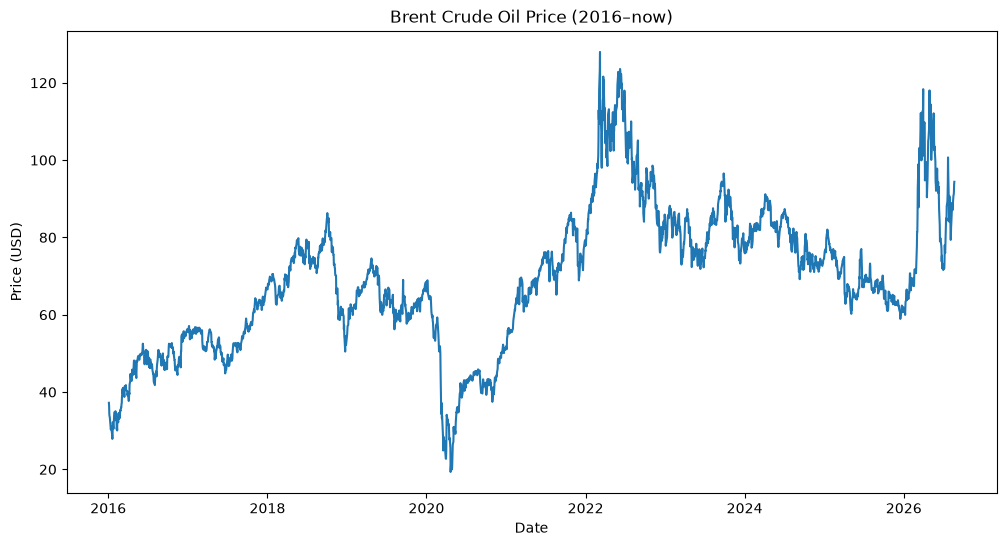

In [22]:
plt.figure(figsize=(12, 6))
plt.plot(brent.index, brent['Close'])
plt.title('Brent Crude Oil Price (2016–now)')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.show()

From the plot, we see Brent fluctuating within a steady range until COVID, where a sharp drop to around $20 occurs due to collapse in demand. From COVID, price rose especially during the Russia-Ukraine war where it peaked above $120 before dropping again. Very recently, the Iran/US conflict caused another sharp rise. The constant shift between calmer ranges and sharp shocks in the last decade alone therefore sets the foundation for a regime-switching approach.

## Baseline: Moving Average Crossover 

A moving average (MA) crossover strategy uses two moving averages calculated over different time windows: a short-term moving average (STMA) and a long-term moving average (LTMA). A crossover of the STMA above the LTMA generates a buy signal - a crossover below generates a sell signal. MAs are relatively straightforward to implement and understand compared to other strategies, hence why it is the baseline of the project. 

We choose the standard 50/200 day pairing by calculating a 50-day STMA and a 200-day LTMA using rolling windows across the full Brent price series. The averages reflect the most recent 50 and 200 trading days at any point in our dataset, rather than for a single fixed period. 

In [23]:
brent['STMA'] = brent['Close'].rolling(window=50).mean()
brent['LTMA'] = brent['Close'].rolling(window=200).mean()
brent.tail()

Price,Close,High,Low,Open,Volume,STMA,LTMA
Date,,,,,,,
2026-08-17,90.870003,91.190002,88.029999,88.720001,33602,83.8626,81.88250
2026-08-18,91.019997,92.010002,90.620003,91.320000,22270,83.8212,82.01300
2026-08-19,91.620003,92.800003,90.419998,91.309998,28039,83.7686,82.14610
2026-08-20,93.779999,94.720001,91.349998,91.510002,27355,83.8152,82.28965
2026-08-21,94.389999,94.809998,92.769997,93.330002,27355,83.8410,82.43715


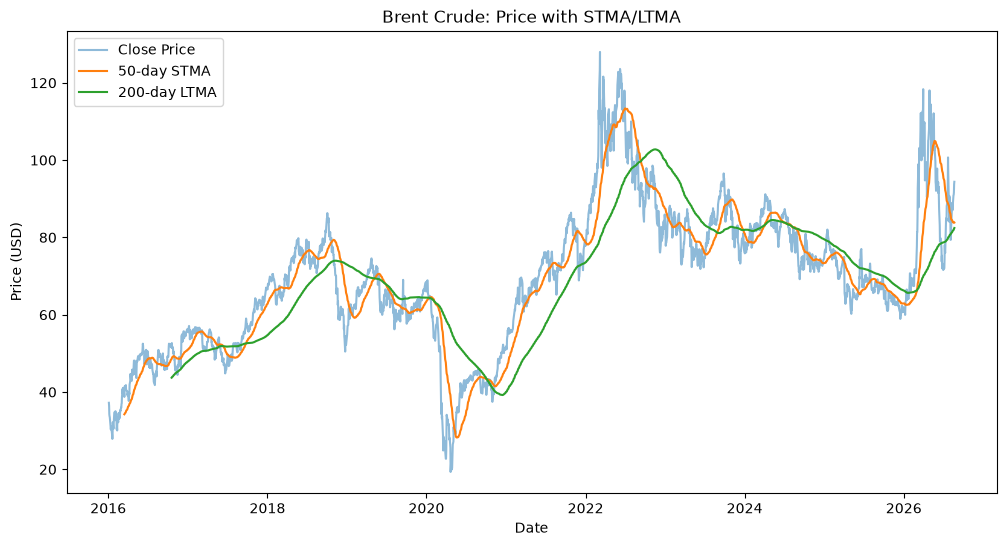

In [24]:
plt.figure(figsize=(12, 6))
plt.plot(brent.index, brent['Close'], label='Close Price', alpha = 0.5)
plt.plot(brent.index, brent['STMA'], label='50-day STMA')
plt.plot(brent.index, brent['LTMA'], label='200-day LTMA')
plt.title('Brent Crude: Price with STMA/LTMA')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

From the plot, the 200-day LTMA (green) is smoother and slower to react to changes in Brent price, compared to the 50-day STMA (orange) that responds more quickly to recent price movements, therefore having sharper turns.

We now generate explicit buy and sell signals from these crossovers by comparing each day's STMA-LTMA relationship with the previous day. A buy signal occurs when the STMA moves from below the LTMA to above it, while a sell signal occurs when it moves from above to below. This lets us identify the exact day on which each crossover occurs, rather than simply tracking whether the STMA is currently above or below the LTMA. 

After identifying the crossover days, we then plot the same series as before, this time with markers added on each crossover point that shows whether to buy or sell.

In [25]:
brent['STMA_above'] = brent['STMA'] > brent['LTMA'] # is STMA above LTMA? 
brent['yesterday_above'] = brent['STMA_above'].shift(1).fillna(False).astype(bool) # was STMA above LTMA yesterday?
brent['BuySignal'] = brent['STMA_above'] & (~brent['yesterday_above']) # buy when STMA crosses above LTMA
brent['SellSignal'] = (~brent['STMA_above']) & brent['yesterday_above'] # sell when STMA crosses below LTMA

brent[brent['BuySignal'] | brent['SellSignal']] # show buy/sell signals only 

Price,Close,High,Low,Open,Volume,STMA,LTMA,STMA_above,yesterday_above,BuySignal,SellSignal
Date,,,,,,,,,,,
2016-10-18,51.680000,52.119999,51.270000,51.689999,28432,48.599800,43.71120,True,False,True,False
2017-06-13,48.720001,48.810001,47.880001,48.270000,26775,51.864000,51.87000,False,True,False,True
2017-09-26,58.439999,59.490002,57.779999,59.200001,28328,52.727600,52.60930,True,False,True,False
2018-12-06,60.060001,61.959999,58.389999,61.700001,60772,73.499601,73.70615,False,True,False,True
2019-05-09,70.389999,70.639999,69.400002,70.230003,46554,69.469400,69.39115,True,False,True,False
2019-06-28,66.550003,66.779999,66.059998,66.650002,32575,67.881000,67.89675,False,True,False,True
2020-01-15,64.000000,64.610001,63.549999,64.459999,34164,64.410000,64.34295,True,False,True,False
2020-02-07,54.470001,55.470001,54.209999,55.360001,43796,63.362000,63.36460,False,True,False,True
2020-10-06,42.650002,42.840000,41.220001,41.520000,37426,43.239600,43.20615,True,False,True,False


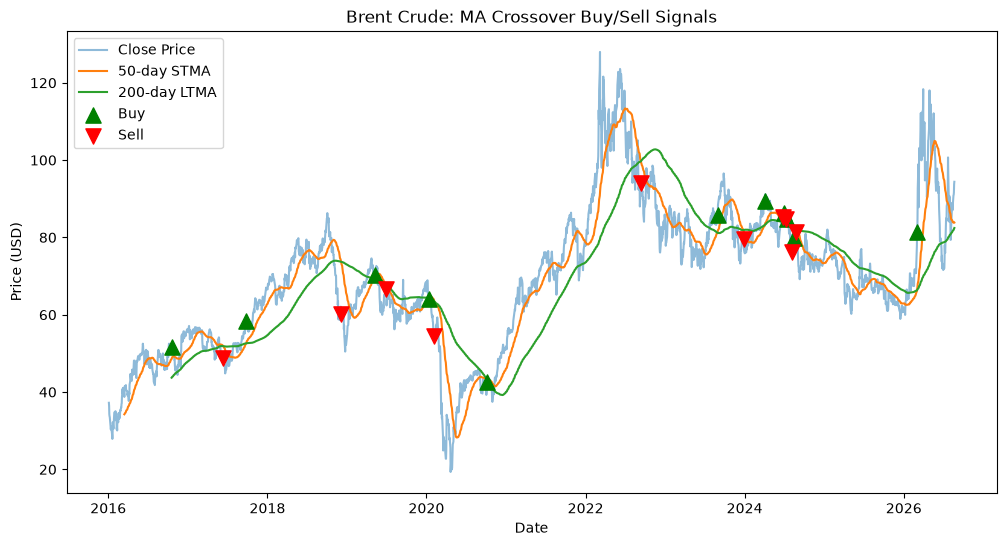

In [26]:
plt.figure(figsize=(12, 6))
plt.plot(brent.index, brent['Close'], label='Close Price', alpha=0.5)
plt.plot(brent.index, brent['STMA'], label='50-day STMA')
plt.plot(brent.index, brent['LTMA'], label='200-day LTMA')

plt.scatter(brent[brent['BuySignal']].index, brent[brent['BuySignal']]['Close'],
            marker='^', color='green', s=120, label='Buy', zorder=5)
plt.scatter(brent[brent['SellSignal']].index, brent[brent['SellSignal']]['Close'],
            marker='v', color='red', s=120, label='Sell', zorder=5)

plt.title('Brent Crude: MA Crossover Buy/Sell Signals')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()

### Backtesting the Baseline Strategy

With buy and sell signals identified, we now backtest the strategy to see how it would have actually performed in four steps: 

1. Position tracking - tracking whether we are in or out of the market in any given day 
2. Strategy returns - calculating return while holding a position 
3. Cumulative performance - compounding these returns into a growth curve to compare against a simple buy-and-hold strategy
4. Summary metric - calculate total return and Sharpe ratio.

In [27]:
brent['Position'] = None 
brent.loc[brent['BuySignal'], 'Position'] = 1 # in the market 
brent.loc[brent['SellSignal'], 'Position'] = 0 # in cash
brent['Position'] = brent['Position'].ffill().fillna(0) # fill forward to maintain position until next signal

brent[['Close', 'BuySignal', 'SellSignal', 'Position']].loc['2016-10-15':'2016-10-25']

Price,Close,BuySignal,SellSignal,Position
Date,,,,
2016-10-17,51.520000,False,False,0
2016-10-18,51.680000,True,False,1
2016-10-19,52.669998,False,False,1
2016-10-20,51.380001,False,False,1
2016-10-21,51.779999,False,False,1
2016-10-24,51.459999,False,False,1
2016-10-25,50.790001,False,False,1


In [28]:
brent['DailyReturn'] = brent['Close'].pct_change() # calculate daily returns
brent['StrategyReturn'] = brent['DailyReturn'] * brent['Position'].shift(1) # shift position to avoid lookahead bias

brent[['Close', 'Position', 'DailyReturn', 'StrategyReturn']].loc['2016-10-15':'2016-10-25'] # show returns for a specific period

Price,Close,Position,DailyReturn,StrategyReturn
Date,,,,
2016-10-17,51.520000,0,-0.008277,-0.0
2016-10-18,51.680000,1,0.003106,0.0
2016-10-19,52.669998,1,0.019156,0.019156
2016-10-20,51.380001,1,-0.024492,-0.024492
2016-10-21,51.779999,1,0.007785,0.007785
2016-10-24,51.459999,1,-0.006180,-0.00618
2016-10-25,50.790001,1,-0.013020,-0.01302


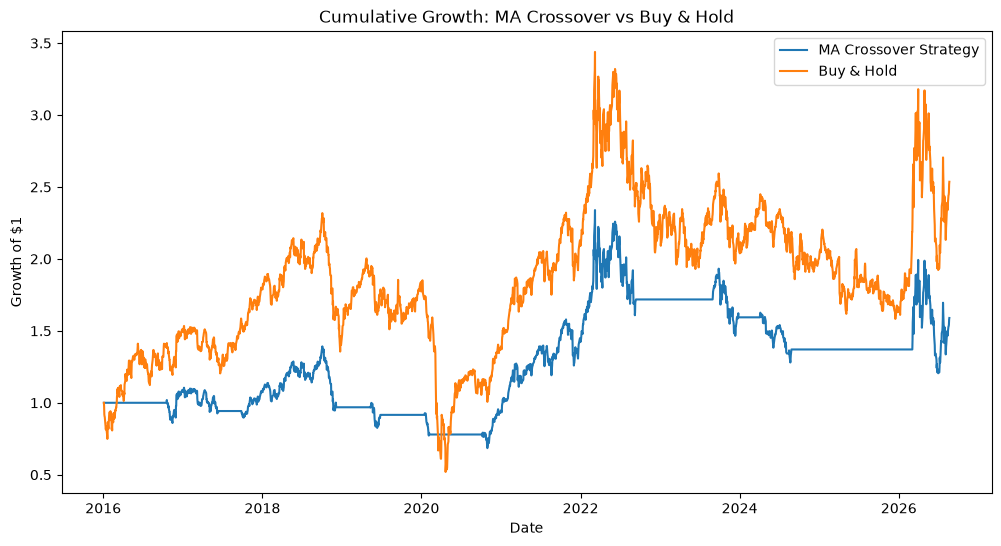

In [29]:
brent['StrategyCumulative'] = (1 + brent['StrategyReturn'].fillna(0)).cumprod() # calculate cumulative returns for the strategy
brent['BuyHoldCumulative'] = (1 + brent['DailyReturn'].fillna(0)).cumprod() # calculate cumulative returns for buy & hold

plt.figure(figsize=(12, 6)) # plot cumulative returns for both strategies
plt.plot(brent.index, brent['StrategyCumulative'], label='MA Crossover Strategy') 
plt.plot(brent.index, brent['BuyHoldCumulative'], label='Buy & Hold') 
plt.title('Cumulative Growth: MA Crossover vs Buy & Hold')
plt.xlabel('Date')
plt.ylabel('Growth of $1')
plt.legend()
plt.show()

In [30]:
strategy_total_return = brent['StrategyCumulative'].iloc[-1] - 1 # calculate total return for the strategy
buyhold_total_return = brent['BuyHoldCumulative'].iloc[-1] - 1 # calculate total return for buy & hold

strategy_sharpe = (brent['StrategyReturn'].mean() / brent['StrategyReturn'].std()) * (252 ** 0.5) # calculate Sharpe ratio for the strategy
buyhold_sharpe = (brent['DailyReturn'].mean() / brent['DailyReturn'].std()) * (252 ** 0.5) # calculate Sharpe ratio for buy & hold

print(f"MA Crossover - Total Return: {strategy_total_return:.1%}, Sharpe Ratio: {strategy_sharpe:.2f}") # print results for the strategy
print(f"Buy & Hold   - Total Return: {buyhold_total_return:.1%}, Sharpe Ratio: {buyhold_sharpe:.2f}") # print results for buy & hold

MA Crossover - Total Return: 58.9%, Sharpe Ratio: 0.30
Buy & Hold   - Total Return: 153.6%, Sharpe Ratio: 0.42


### Baseline Conclusion 

From the cumulative growth plot, buy-and-hold easily outperforms the MA crossover strategy on both total return (153.6% vs 58.9%) and Sharpe ratio (0.42 vs 0.30). We see that the strategy avoids some drawdowns by sitting in cash, but its lagging signals mean it re-enters late, missing a noticeable portion in each recovery. 

Therefore our baseline is not just the MA crossover, but now buy-and-hold too. We will now see if our regime-switching models are able to outperform both strategies. 

## Geometric Brownian Motion 

Geometric Brownian Motion (GBM) is a stochastic model commonly used to describe the evolution of asset prices over time. It assumes that price movements are driven by two parameters: drift (μ) which represents the average rate of return, and volatility (σ) which represents the randomness of price movements.

Here, we estimate μ and σ from Brent's historical returns and use these parameters to simulate future price paths under the GBM model. This gives us a baseline for understanding how Brent prices evolve under a model that assumes continuous stochastic growth, before comparing this behaviour with the mean-reverting OU process. Before this, we explain the difference between percentage returns and log returns and why GBM works with log returns rather than the percentage returns we used in our baseline strategy. 

### Percentage and Log Returns 

Unlike ordinary percentage returns, which compound multiplicatively over time, log returns are additive.

Suppose Brent oil is at $100, then it increases by 10% and then falls by 10%. Its price moves from $100 → $110 → $99, giving a total return of -1%. Simply adding the two percentage returns would incorrectly suggest a 0% return.

Log returns are calculated as the natural logarithm of the ratio of today's price and yesterday's price. Their key property is that they add across time. Therefore, log return over multiple periods is simply the sum of the log returns within those periods. This is particularly useful for GBM, where the logarithm of the asset price follows an additive stochastic process.

We therefore calculate Brent's daily log returns and use their properties to estimate the parameters required for the GBM simulations.

In [ ]:
brent['LogReturn'] = np.log(brent['Close'] / brent['Close'].shift(1)) # calculate log returns
brent[['Close', 'DailyReturn', 'LogReturn']].tail() 

Price,Close,DailyReturn,LogReturn
Date,,,
2026-08-17,90.870003,0.026548,0.026201
2026-08-18,91.019997,0.001651,0.001649
2026-08-19,91.620003,0.006592,0.006570
2026-08-20,93.779999,0.023576,0.023302
2026-08-21,94.389999,0.006505,0.006484


In [ ]:
mu = brent['LogReturn'].mean() * 252
sigma = brent['LogReturn'].std() * np.sqrt(252)

print(f"Annualized drift (μ): {mu:.4f}")
print(f"Annualized volatility (σ): {sigma:.4f}")

Annualized drift (μ): 0.0877
Annualized volatility (σ): 0.4118


The estimated GBM parameters give a drift (μ) of 0.0877 and annualised volatility (σ) of 0.4118. This suggests an average annual upward drift of approximately 8.8%, alongside relatively high annualised volatility of around 41.2%.

The estimated volatility reflects the substantial price movements present in the historical data, including periods such as the COVID-19 crash, the 2022 oil price spike and the 2026 Strait of Hormuz disruption. The relatively high volatility is consistent with the sharp movements observed in the price series and highlights the uncertainty that GBM will need to capture when simulating future Brent prices.

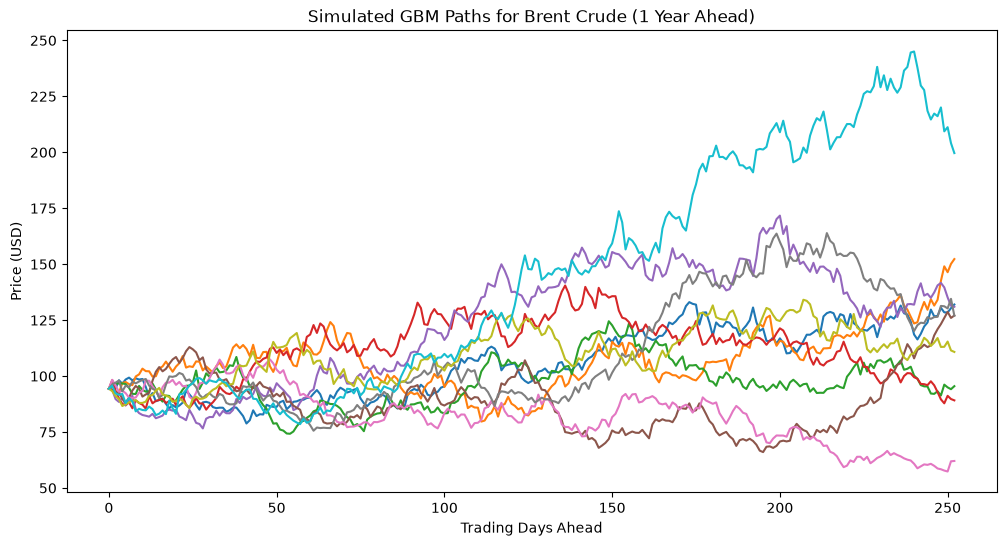

In [36]:
np.random.seed(42)  # for reproducibility

S0 = brent['Close'].iloc[-1]   # last observed price
T = 1                          # time horizon in years
dt = 1/252                     # time step in years (daily)
N = int(T/dt)                  # number of time steps
n_paths = 10                   # number of simulated paths

simulated_paths = np.zeros((N+1, n_paths)) 
simulated_paths[0] = S0 

for t in range(1, N+1):
    Z = np.random.standard_normal(n_paths)
    simulated_paths[t] = simulated_paths[t-1] * np.exp((mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z) # simulate GBM paths

plt.figure(figsize=(12, 6)) # plot the simulated paths
plt.plot(simulated_paths)
plt.title('Simulated GBM Paths for Brent Crude (1 Year Ahead)')
plt.xlabel('Trading Days Ahead')
plt.ylabel('Price (USD)')
plt.show()

### Evaluating GBM 

The simulated paths show noticeable dispersion over the one-year horizon - all paths starting from approximately $95, the final observed Brent price before diverging into various outcomes. This wide spread is consistent with the relatively high estimated volatility of σ ≈ 41%, while the absence of any fixed long-run level allows the paths to move freely away from their starting point.

However, once a path moves away from its starting point, nothing in the model pulls it back towards a typical price level. This contrasts with earlier price plots that show periods of sharp movements followered by partial reversals. This highlights a key limitation of modelling oil prices using GBM because the paths have no intention for mean reversion. This provides motivation for investigating the Ornstein-Uhlenbeck (OU) process, which directly incorporates mean-reverting behaviour.

## Ornstein-Uhlenbeck (OU) Process 

The Ornstein-Uhlenbeck (OU) process provides an alternative to GBM by explicitly modelling mean-reverting behaviour. Instead of prices drifting freely away from their starting point, OU assumes that the price is pulled towards a long-run average, with the strength of this pull depending on how far the price has moved from that average.

The model is described by three parameters:

1. θ (theta) — the speed of mean reversion, determining how quickly the price is pulled back towards its long-run mean.
2. μ (mu) — the long-run mean price that the process tends to revert towards (different to μ in GBM)
3. σ (sigma) — the volatility of the process, representing the randomness of price movements.

Given the lack of mean reversion in the GBM simulations, the OU process allows us to test whether this behaviour provides a more realistic representation of Brent's historical price dynamics. We will estimate these three parameters from the historical data before using them to simulate future price paths.

### Estimating the OU parameters 

Estimating the OU parameters

The continuous-time OU process is given by:

dS
t
	​

=θ(μ−S
t
	​

)dt+σdW
t
	​


The first term represents mean reversion, while the second captures random price movements. If the current price S
t
	​

 is below the long-run mean μ, the mean-reverting term is positive and pushes the price upwards. If S
t
	​

 is above μ, the term becomes negative and pulls the price downwards. The parameter θ controls the strength of this pull.

Our data, however, consists of discrete daily observations rather than a continuous price process. We therefore approximate the OU equation over one day:

S
t+1
	​

−S
t
	​

≈θ(μ−S
t
	​

)Δt+ϵ
t
	​


Rearranging gives:

ΔS
t
	​

≈θμΔt−θΔtS
t
	​

+ϵ
t
	​


This has the form of a linear regression:


Therefore, we can estimate the OU parameters from a regression of daily price changes against the previous day's price. A negative slope is consistent with mean-reverting behaviour: higher starting prices are associated with more negative subsequent price changes, while lower starting prices are associated with more positive changes.

From the estimated slope and intercept, we can then recover θ and μ, while the regression residuals provide an estimate of σ.